In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append('../src')

from pathlib import Path
import polars as pl
from matplotlib import pyplot as plt
import numpy as np

plato_data_directory = Path('/STER/mamsie/tess/TIC/plato_fov/')

TODO:
- Run on sector 1, 2 and 3
- point Nik to parquet with predictions
- Add Simon features: https://arxiv.org/abs/2205.03020
- Select the best feature from the highly correlated clusters, or combine them with PCA?
- ~~Understand why Cepheids look so weird -> TGLC calibration.~~ Are they weird in QLP too?
- Report on high probability missclasifications
- Calibration/reliability curves
- Disagreement between RF and nnet
- Design semi-supervised strategy for labeling v2

# Training data

## Dataset cleaning

In [ ]:
df_training_set = pl.read_csv(plato_data_directory / 'training_df_try3.csv')
df_training_set.head()

In [ ]:
# Unique paths and unique tics
df_training_set.height, df_training_set.unique('path').height, df_training_set.unique('tic').height

In [ ]:
# Remove duplicates
df_training_set = df_training_set.unique('path')

In [ ]:
# Make training set compatible with inference parquets
df_training_set.rename({'path': 'FilePath'}).write_parquet(plato_data_directory / 'training_df_try3.parquet')

In [ ]:
# Sources per class
df_training_set.group_by('label').len().sort('label')

In [ ]:
# sanity check
df_training_set['path'].is_duplicated().sum()

In [ ]:
%%time

# Have negative fluxes
from light_curves import read_fits_lc
from tqdm.notebook import tqdm
from joblib import Parallel, delayed

def count_zero_fluxes(path):
    try: 
        return np.sum(read_fits_lc(path)[1] < 0.0).item()
    except:
        return None
        
neg_count = Parallel(n_jobs=16, backend='loky')(delayed(count_zero_fluxes)(path) for path in df_training_set['path'].to_list())
   

#for row in tqdm(df_training_features.iter_rows(named=True), total=df_training_features.height):
#    neg_count.append(np.sum(read_fits_lc(row['path'])[1] < 0))
    

In [ ]:
df_neg_flux_count = pl.DataFrame({
    'path': df_training_set['path'].to_list(),
    'neg_flux_count': neg_count
})
df_neg_flux_count.filter(
    pl.col('neg_flux_count').gt(0) | pl.col('neg_flux_count').is_null()
)

## Clean dataset

In [2]:
df_training_set = pl.read_parquet(plato_data_directory / 'training_df_try7.parquet').select(['path', 'label', 'GaiaID'])#.rename({'FilePath': 'path'})
print(df_training_set.height, df_training_set.columns)
df_training_set.group_by('label').len().sort('label')

26952 ['path', 'label', 'GaiaID']


label,len
str,u32
"""APERIODIC""",1521
"""CONTACT_ROT""",3577
"""DSCT_BCEP""",6778
"""ECLIPSE""",1316
"""GDOR_SPB""",4321
"""INSTRUMENT/JUNK""",5691
"""RRLYR_CEPH""",1174
"""SOLARLIKE""",2574


## Features

In [3]:
# Loading features
df_training_features = pl.read_parquet('../results/training_set/')
print(df_training_features.height)
df_training_features = df_training_features.drop_nans().drop_nulls()
print(df_training_features.height)
df_training_features = df_training_features.join(df_training_set.select(['path', 'label', 'GaiaID']), on='path')
print(df_training_features.height)
df_training_features = df_training_features.filter(pl.col('num_negative_fluxes').eq(0))
print(df_training_features.height)
# Average values per class
#df_training_features.drop(['tic', 'path']).group_by('label').mean().sort('label')

# Log transforms for features with large dynamic range

log_columns = [
    'fourier_amplitude_1', 'fourier_amplitude_2', 'fourier_amplitude_3', 'fourier_amplitude_4', 'fourier_amplitude_half',
    'flux_std', 'flux_iqr', 'flux_amplitude', 'flux_mad', 'flux_amplitude', 'flux_largest_departure', 'flux_percent_difference', 'max_slope',
    'ls_fundamental_frequency', 'ls_fundamental_fap',
]
asinh_columns = ['flux_skewness', 'flux_kurtosis']

df_training_features = df_training_features.with_columns(
    *[pl.col(col).log10() for col in [log_columns]],
    *[pl.col(col).arcsinh() for col in [asinh_columns]]
)
df_training_features = df_training_features.with_columns(
    (pl.col('fourier_amplitude_2') - pl.col('fourier_amplitude_1')).alias('relative_fourier_amplitude_2'),
    pl.col('fourier_amplitude_3').sub(pl.col('fourier_amplitude_1')).alias('relative_fourier_amplitude_3'),
    pl.col('fourier_amplitude_4').sub(pl.col('fourier_amplitude_1')).alias('relative_fourier_amplitude_4'),
    pl.col('fourier_amplitude_half').sub(pl.col('fourier_amplitude_1')).alias('relative_fourier_amplitude_half'),
)

df_training_features = df_training_features.drop([
    'num_negative_fluxes', 'ls_frequency_top_2', 'ls_frequency_top_3', #diagnostics features
    'fourier_amplitude_2', 'fourier_amplitude_3', 'fourier_amplitude_4', 'fourier_amplitude_half', # renormalized features
    'CO_trev_3_num', 'SP_Summaries_welch_rect_peakPower_5', 'ST_LocalExtrema_n100_medianmax', 'AC_nl_001'
])

26912
26912
26912
26911


In [4]:
# Average values per class
df_training_features.drop(['GaiaID', 'path']).group_by('label').mean().sort('label')

label,flux_std,flux_skewness,flux_kurtosis,flux_iqr,flux_amplitude,flux_mad,flux_largest_departure,flux_percent_difference,flux_ratio_mid20,flux_ratio_mid45,flux_ratio_mid50,flux_ratio_mid65,flux_ratio_mid80,max_slope,acf_lag_first_below_05,acf_val_lag1,acf_lag_peak1,acf_val_peak1,acf_lag_peak2,acf_val_peak2,ls_fundamental_frequency,ls_fundamental_fap,fourier_amplitude_1,fourier_relative_phase_2,fourier_relative_phase_3,fourier_relative_phase_4,fourier_r2_fit,relative_fourier_amplitude_2,relative_fourier_amplitude_3,relative_fourier_amplitude_4,relative_fourier_amplitude_half
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""APERIODIC""",-3.181001,-0.55356,1.76314,-3.13899,-3.002165,-3.440535,-2.456042,-2.701138,0.13573,0.244424,0.366146,0.514808,0.730565,-0.851739,0.028874,0.314839,2.595132,0.107919,3.649014,0.021861,-0.156666,-9.642552,-3.716836,0.102019,0.013641,0.120713,0.074278,-0.541871,-0.66068,-0.70989,-0.546333
"""CONTACT_ROT""",-2.195005,-0.169453,0.095886,-2.035895,-2.010071,-2.348288,-1.681993,-1.709958,0.194225,0.338936,0.485474,0.642637,0.828489,-0.267416,0.091155,0.722522,1.24318,0.538946,2.018935,0.516575,0.11201,-186.66503,-2.241278,-0.099771,-0.01025,0.050729,0.637814,-1.05769,-1.361979,-1.606269,-0.88336
"""DSCT_BCEP""",-2.601547,-0.079642,0.240416,-2.469844,-2.396751,-2.770975,-2.029956,-2.095709,0.162296,0.28868,0.424793,0.581719,0.78688,-0.308693,0.022877,0.012126,1.140258,0.362324,1.765903,0.259545,1.091497,-95.68101,-2.744898,-0.108247,-0.022982,-0.013678,0.325492,-1.444828,-1.504587,-1.507048,-1.541468
"""ECLIPSE""",-1.704482,-1.728078,2.840834,-2.181063,-1.622393,-2.510201,-0.973269,-1.321029,0.066588,0.120768,0.186169,0.283318,0.505095,0.256899,0.084616,0.862015,1.901741,0.466754,2.816239,0.402714,-0.038609,-66.140787,-1.923451,0.0458,0.016716,0.095927,0.530282,-0.181628,-0.28794,-0.427965,-0.619888
"""GDOR_SPB""",-2.670549,-0.006173,0.457786,-2.55732,-2.464744,-2.860107,-2.084148,-2.16369,0.15281,0.273478,0.407306,0.565493,0.7767,-0.688665,0.089003,0.764851,0.893876,0.461524,1.674361,0.371825,0.174248,-101.665222,-2.801393,-0.037383,0.01029,0.034602,0.349558,-1.119663,-1.481789,-1.596139,-1.138527
"""INSTRUMENT/JUNK""",-2.597961,-0.190954,1.151428,-2.524905,-2.407527,-2.825875,-1.92678,-2.106497,0.142337,0.256116,0.383471,0.53759,0.753902,-0.340999,0.032021,0.298284,2.686395,0.12387,3.341283,0.085675,0.101436,-18.010625,-3.075435,0.243796,0.323581,-0.102042,0.108044,-0.553695,-0.651181,-0.824162,-0.726672
"""RRLYR_CEPH""",-0.824723,0.350887,-0.851761,-0.587831,-0.652868,-0.947087,-0.459738,-0.347074,0.257647,0.433362,0.591605,0.739689,0.893411,0.92851,0.084933,0.926795,0.530526,0.914614,1.063754,0.850496,0.303146,-287.933439,-0.719916,-1.047305,-1.287664,0.453987,0.965943,-0.55029,-0.842586,-1.156201,-2.127274
"""SOLARLIKE""",-3.053134,-0.340285,1.147748,-2.970547,-2.856781,-3.271769,-2.37338,-2.555746,0.143221,0.257842,0.385755,0.539872,0.754767,-0.764653,0.03834,0.486305,3.197294,0.060621,3.767985,0.021336,0.145414,-12.478885,-3.535489,0.083221,0.061257,0.027048,0.081145,-0.701262,-0.815332,-0.90609,-0.605269


In [5]:
# Train test split based on tics rather than on paths
#from sklearn.model_selection import train_test_split
#tic, y = df_training_features.unique('GaiaID')[['GaiaID', 'label']].sort('GaiaID').to_numpy().T
#print(df_training_set.height, df_training_set.columns)
#df_training_set.group_by('label').len().sort('label')
#tic_train, tic_test, _, _ = train_test_split(tic, y, stratify=y, test_size=0.3, random_state=1234, shuffle=True)

# Use same partitions as neural net
tic_train = pl.read_csv(plato_data_directory / 'training_df_try7_train_gaiaids.csv').to_series().cast(pl.String).to_list()
tic_val = pl.read_csv(plato_data_directory / 'training_df_try7_val_gaiaids.csv').to_series().cast(pl.String).to_list()
tic_train = tic_train + tic_val
tic_test = pl.read_csv(plato_data_directory / 'training_df_try7_test_gaiaids.csv').to_series().cast(pl.String).to_list()

df_train = df_training_features.filter(pl.col('GaiaID').is_in(tic_train))
path_train = df_train['path'].to_numpy()
y_train = df_train['label'].to_numpy()
X_train = df_train.drop(['GaiaID', 'path', 'label']).to_numpy()
y_names = np.unique(y_train)
df_test = df_training_features.filter(pl.col('GaiaID').is_in(tic_test))
path_test = df_test['path'].to_numpy()
y_test = df_test['label'].to_numpy()
X_test = df_test.drop(['GaiaID', 'path', 'label']).to_numpy()
X_name = np.array(df_test.drop(['GaiaID', 'path', 'label']).columns)
X_train.shape, X_test.shape

((21473, 31), (5438, 31))

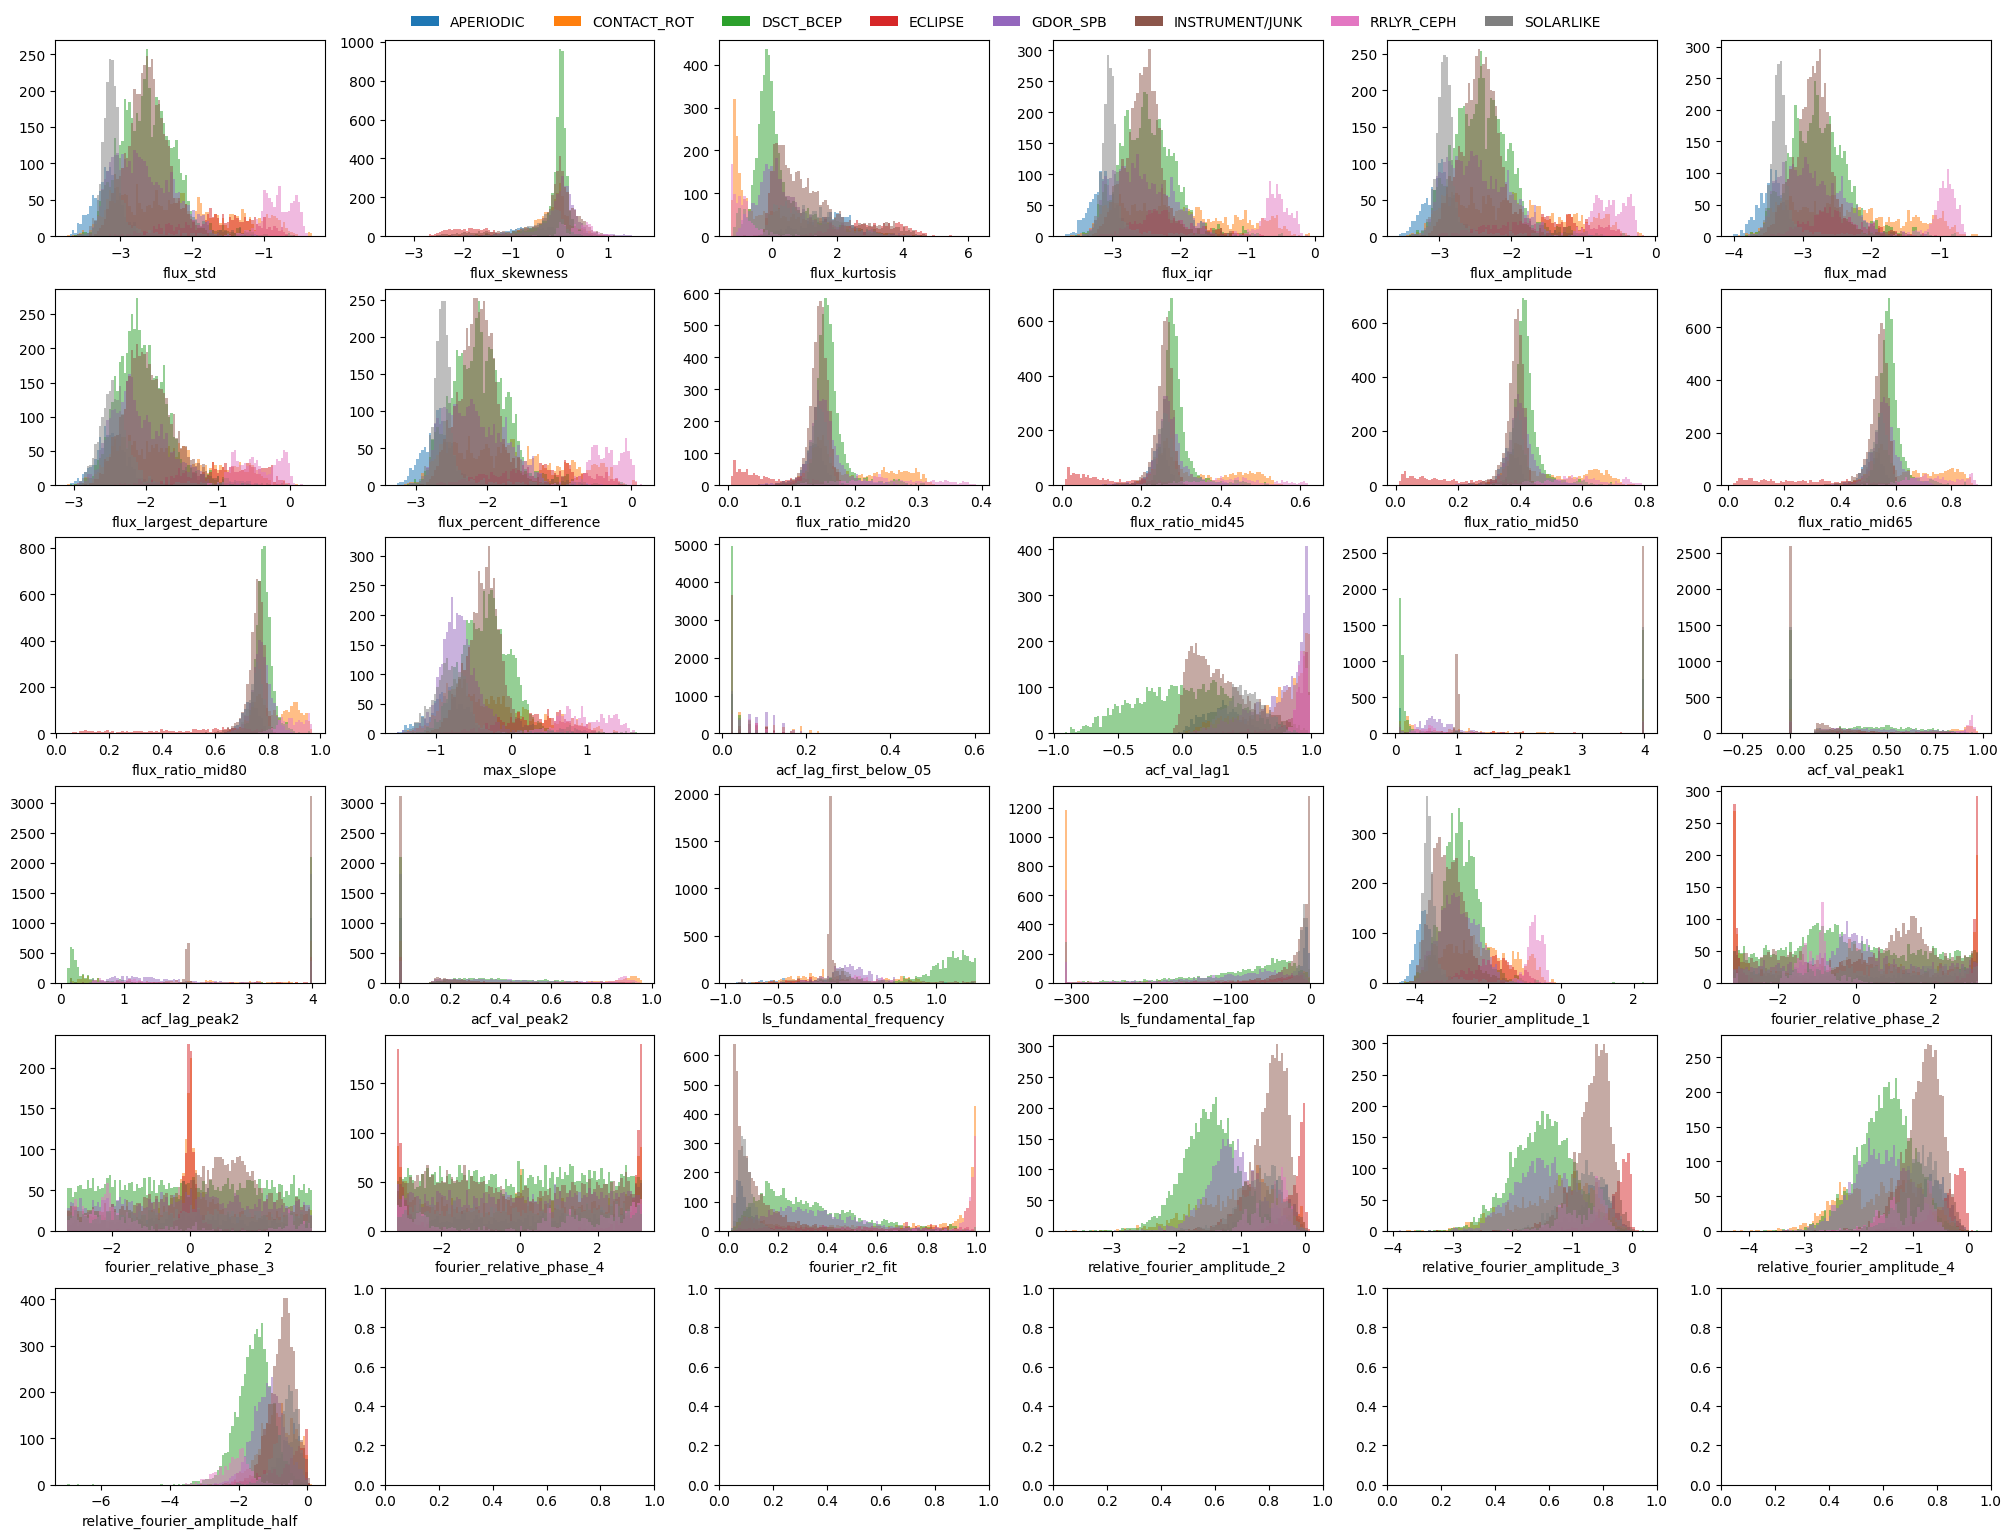

In [6]:
# Visualizing the features
bins = 100

fig, axs = plt.subplots(6, 6, figsize=(20, 15), constrained_layout=True)
for ax, col, col_name in zip(axs.ravel(), X_train.T, X_name):
    hrange = (np.amin(col), np.amax(col))
    for name in y_names:
        mask = y_train == name
        ax.hist(col[mask], range=hrange, bins=bins, label=name, alpha=0.5)
    ax.set_xlabel(col_name)

handles, labels = axs.ravel()[0].get_legend_handles_labels()
leg = fig.legend(handles, labels, loc="upper center", ncol=len(labels), bbox_to_anchor=(0.5, 1.02), frameon=False)
for h in leg.legend_handles:
    h.set_alpha(1.0)

In [7]:
import numpy as np
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

corr = np.corrcoef(X_train, rowvar=False)
dist = 1 - np.abs(corr)
dist = 0.5 * (dist + dist.T)
np.fill_diagonal(dist, 0.0)

link = linkage(squareform(dist), method='average')
clusters = fcluster(link, t=0.05, criterion='distance') # 95% correlation

selected_features = []
for c in np.unique(clusters):
    idx = np.where(clusters == c)[0]
    print(c, [X_name[i].item() for i in idx])
    selected_features.append(idx[0]) # Choose first, how to best do this?
selected_features = np.sort(np.array(selected_features))

X_train = X_train[:, selected_features]
X_test  = X_test[:, selected_features]

1 ['fourier_relative_phase_2']
2 ['fourier_relative_phase_4']
3 ['flux_ratio_mid20', 'flux_ratio_mid45', 'flux_ratio_mid50']
4 ['flux_ratio_mid65']
5 ['flux_ratio_mid80']
6 ['flux_skewness']
7 ['flux_kurtosis']
8 ['relative_fourier_amplitude_3']
9 ['relative_fourier_amplitude_4']
10 ['relative_fourier_amplitude_2']
11 ['ls_fundamental_frequency']
12 ['relative_fourier_amplitude_half']
13 ['acf_lag_first_below_05']
14 ['acf_val_lag1']
15 ['acf_lag_peak1']
16 ['acf_lag_peak2']
17 ['flux_std', 'flux_iqr', 'flux_amplitude', 'flux_mad', 'flux_percent_difference', 'fourier_amplitude_1']
18 ['flux_largest_departure']
19 ['max_slope']
20 ['ls_fundamental_fap']
21 ['fourier_r2_fit']
22 ['acf_val_peak1']
23 ['acf_val_peak2']
24 ['fourier_relative_phase_3']


## Classifiers

In [8]:
# Rescaling the features
from sklearn.preprocessing import QuantileTransformer, StandardScaler, RobustScaler

#rng = np.random.RandomState(0)
#qt = QuantileTransformer(n_quantiles=1000, random_state=0)
#X_train_prec3 = qt.fit_transform(X_train)
#X_prec1 = StandardScaler().fit_transform(X)
scaler = RobustScaler()
X_train_pre = scaler.fit_transform(X_train)
X_test_pre = scaler.transform(X_test)

### K-nn

In [9]:
# k-nn classifier

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import GridSearchCV

clf = GridSearchCV(KNeighborsClassifier(n_jobs=4), cv=5, param_grid={'n_neighbors': [15, 25], 'weights': ['uniform', 'distance']}, scoring='f1_macro')
clf.fit(X_train_pre, y_train)
print(classification_report(y_true=y_test, y_pred=clf.predict(X_test_pre)))

                 precision    recall  f1-score   support

      APERIODIC       0.74      0.62      0.67       317
    CONTACT_ROT       0.93      0.65      0.77       701
      DSCT_BCEP       0.96      0.94      0.95      1341
        ECLIPSE       0.95      0.86      0.90       279
       GDOR_SPB       0.80      0.86      0.83       914
INSTRUMENT/JUNK       0.81      0.96      0.87      1108
     RRLYR_CEPH       0.91      0.98      0.94       216
      SOLARLIKE       0.70      0.74      0.72       562

       accuracy                           0.85      5438
      macro avg       0.85      0.83      0.83      5438
   weighted avg       0.86      0.85      0.85      5438



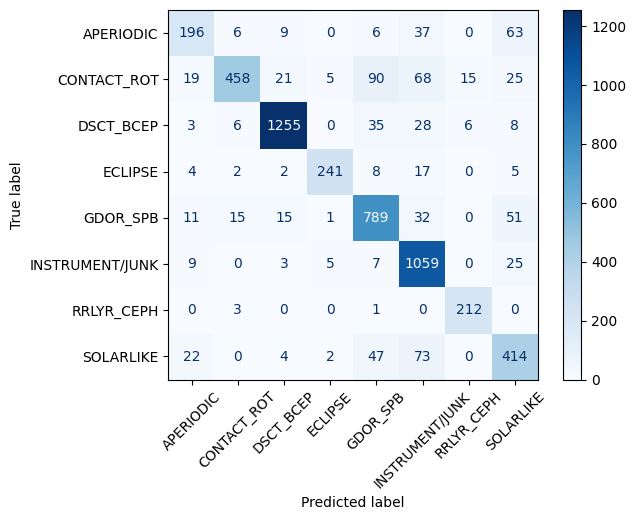

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay

y_test_pred = clf.predict(X_test_pre)
ConfusionMatrixDisplay.from_predictions(y_true=y_test, y_pred=y_test_pred, cmap=plt.cm.Blues, xticks_rotation=45)

In [11]:
# Best hyperparameters 
pl.DataFrame(clf.cv_results_).sort('rank_test_score').drop(['^.*_time$', 'params'])

param_n_neighbors,param_weights,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
i64,str,f64,f64,f64,f64,f64,f64,f64,i32
15,"""distance""",0.831086,0.822619,0.834574,0.816961,0.799917,0.821031,0.012242,1
15,"""uniform""",0.830214,0.82357,0.834183,0.814236,0.793837,0.819208,0.014372,2
25,"""distance""",0.830321,0.813646,0.832273,0.812037,0.797503,0.817156,0.012858,3
25,"""uniform""",0.826444,0.815863,0.831446,0.81007,0.791636,0.815092,0.013945,4


### Random Forest

In [12]:
%%time

# Random Forest
from sklearn.ensemble import RandomForestClassifier

clf = GridSearchCV(RandomForestClassifier(n_jobs=1), n_jobs=16, cv=5, param_grid={
    'n_estimators': [50, 100, 200], 'class_weight': ['balanced', None], 'max_depth': [10, 15]
}, scoring='f1_macro')

clf.fit(X_train_pre, y_train)
print(classification_report(y_true=y_test, y_pred=clf.predict(X_test_pre), digits=3))

                 precision    recall  f1-score   support

      APERIODIC      0.816     0.798     0.807       317
    CONTACT_ROT      0.892     0.790     0.838       701
      DSCT_BCEP      0.977     0.967     0.972      1341
        ECLIPSE      0.943     0.889     0.915       279
       GDOR_SPB      0.877     0.889     0.883       914
INSTRUMENT/JUNK      0.881     0.969     0.923      1108
     RRLYR_CEPH      0.995     0.958     0.976       216
      SOLARLIKE      0.812     0.813     0.812       562

       accuracy                          0.902      5438
      macro avg      0.899     0.884     0.891      5438
   weighted avg      0.902     0.902     0.901      5438

CPU times: user 17.2 s, sys: 111 ms, total: 17.4 s
Wall time: 54.2 s


In [13]:
# Best hyperparameters
pl.DataFrame(clf.cv_results_).sort('rank_test_score').drop(['^.*_time$', 'params'])

param_class_weight,param_max_depth,param_n_estimators,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
str,i64,i64,f64,f64,f64,f64,f64,f64,f64,i32
"""balanced""",15,200,0.887971,0.886225,0.890614,0.885144,0.85455,0.880901,0.013305,1
null,15,200,0.890839,0.889036,0.890869,0.883821,0.848109,0.880535,0.016416,2
null,15,100,0.88847,0.888432,0.893533,0.880491,0.847256,0.879636,0.01672,3
null,15,50,0.889119,0.886289,0.893075,0.880398,0.847552,0.879287,0.016396,4
"""balanced""",15,100,0.88784,0.886544,0.892377,0.879703,0.848095,0.878912,0.015935,5
…,…,…,…,…,…,…,…,…,…,…
null,10,100,0.875308,0.871637,0.877788,0.865708,0.829344,0.863957,0.017778,8
null,10,50,0.874952,0.869654,0.878293,0.866451,0.826093,0.863089,0.018947,9
"""balanced""",10,200,0.866806,0.869455,0.867116,0.863155,0.835875,0.860481,0.012467,10


Text(0.5, 1.0, 'Full dataset')

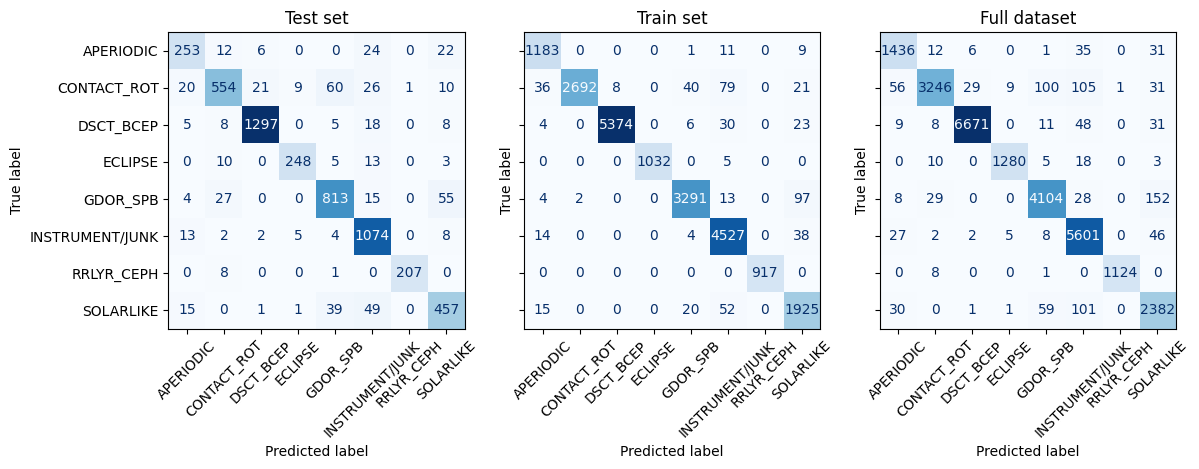

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axs = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
y_test_pred = clf.predict(X_test_pre)
ConfusionMatrixDisplay.from_predictions(y_true=y_test, y_pred=y_test_pred, cmap=plt.cm.Blues, xticks_rotation=45, ax=axs[0], colorbar=False)
axs[0].set_title('Test set')
ConfusionMatrixDisplay.from_predictions(y_true=y_train, y_pred=clf.predict(X_train_pre), cmap=plt.cm.Blues, xticks_rotation=45, ax=axs[1], colorbar=False)
axs[1].set_title('Train set')
ConfusionMatrixDisplay.from_predictions(y_true=np.concatenate([y_train, y_test]), y_pred=np.concatenate([clf.predict(X_train_pre), clf.predict(X_test_pre)], axis=0), cmap=plt.cm.Blues, xticks_rotation=45, ax=axs[2], colorbar=False)
axs[2].set_title('Full dataset')

## Feature importance (RF only)

Text(0.5, 1.0, 'Random Forest Mean Decrease in Impurity')

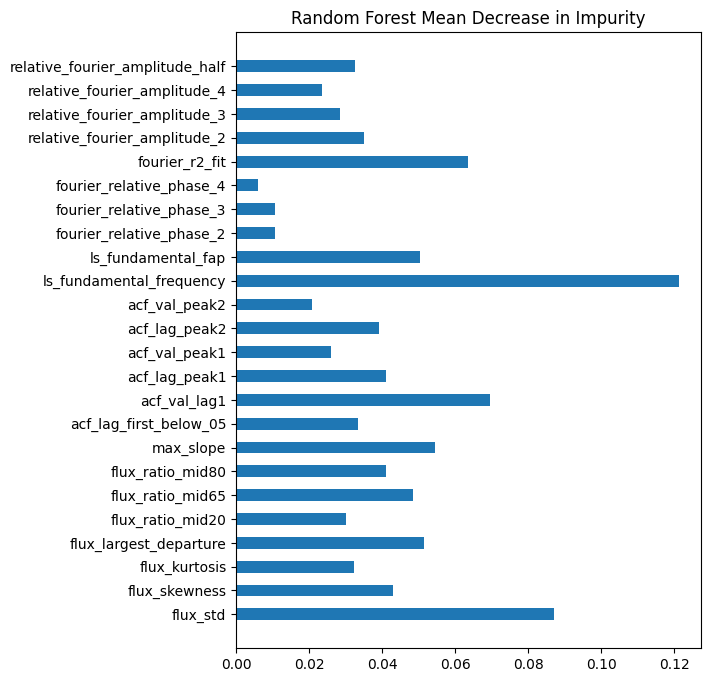

In [15]:
fig, ax = plt.subplots(figsize=(6, 8))

#RF MDI has a few drabacks
# Biased toward high-cardinality or continuous features (i.e. features with many possible split points are favored)
# Inflated importance for correlated predictors.
# It is a training-set measure. It does not evaluate generalization impact.

ax.barh(X_name[selected_features], clf.best_estimator_.feature_importances_, height=0.5)
ax.set_title('Random Forest Mean Decrease in Impurity')

CPU times: user 2.25 s, sys: 2.22 s, total: 4.46 s
Wall time: 12.7 s


Text(0.5, 1.0, 'Random Forest, Permutation importance')

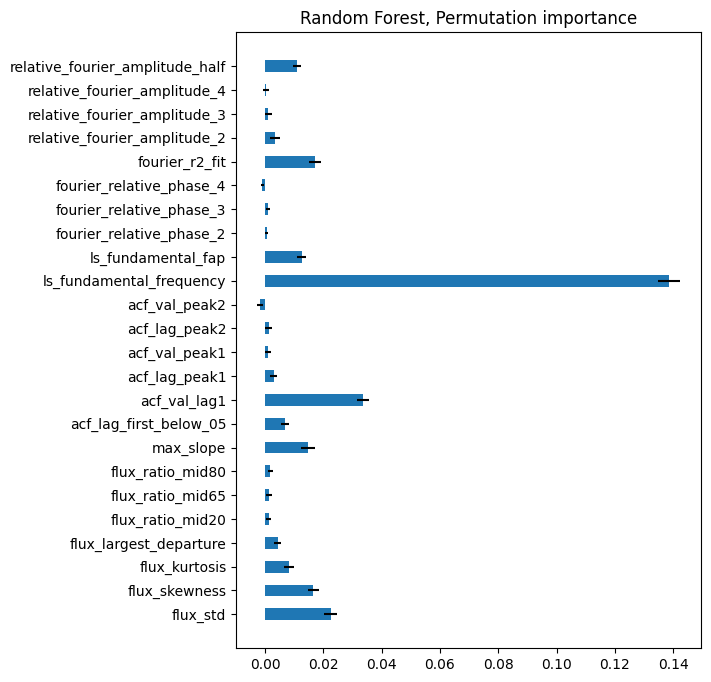

In [16]:
%%time
from sklearn.inspection import permutation_importance

# Permutation importance drawbacks:
# Underestimates importance under feature correlation.
# If two features encode the same information, permuting one may not hurt performance.

pi_global = permutation_importance(clf.best_estimator_, X_test_pre, y_test, scoring="f1_macro", n_repeats=30, random_state=0, n_jobs=16)

fig, ax = plt.subplots(figsize=(6, 8))
ax.barh(y=np.array(X_name)[np.array(selected_features)], width=pi_global.importances_mean, xerr=pi_global.importances_std, height=0.5)
ax.set_title('Random Forest, Permutation importance')

CPU times: user 2.49 s, sys: 2.16 s, total: 4.65 s
Wall time: 12.6 s


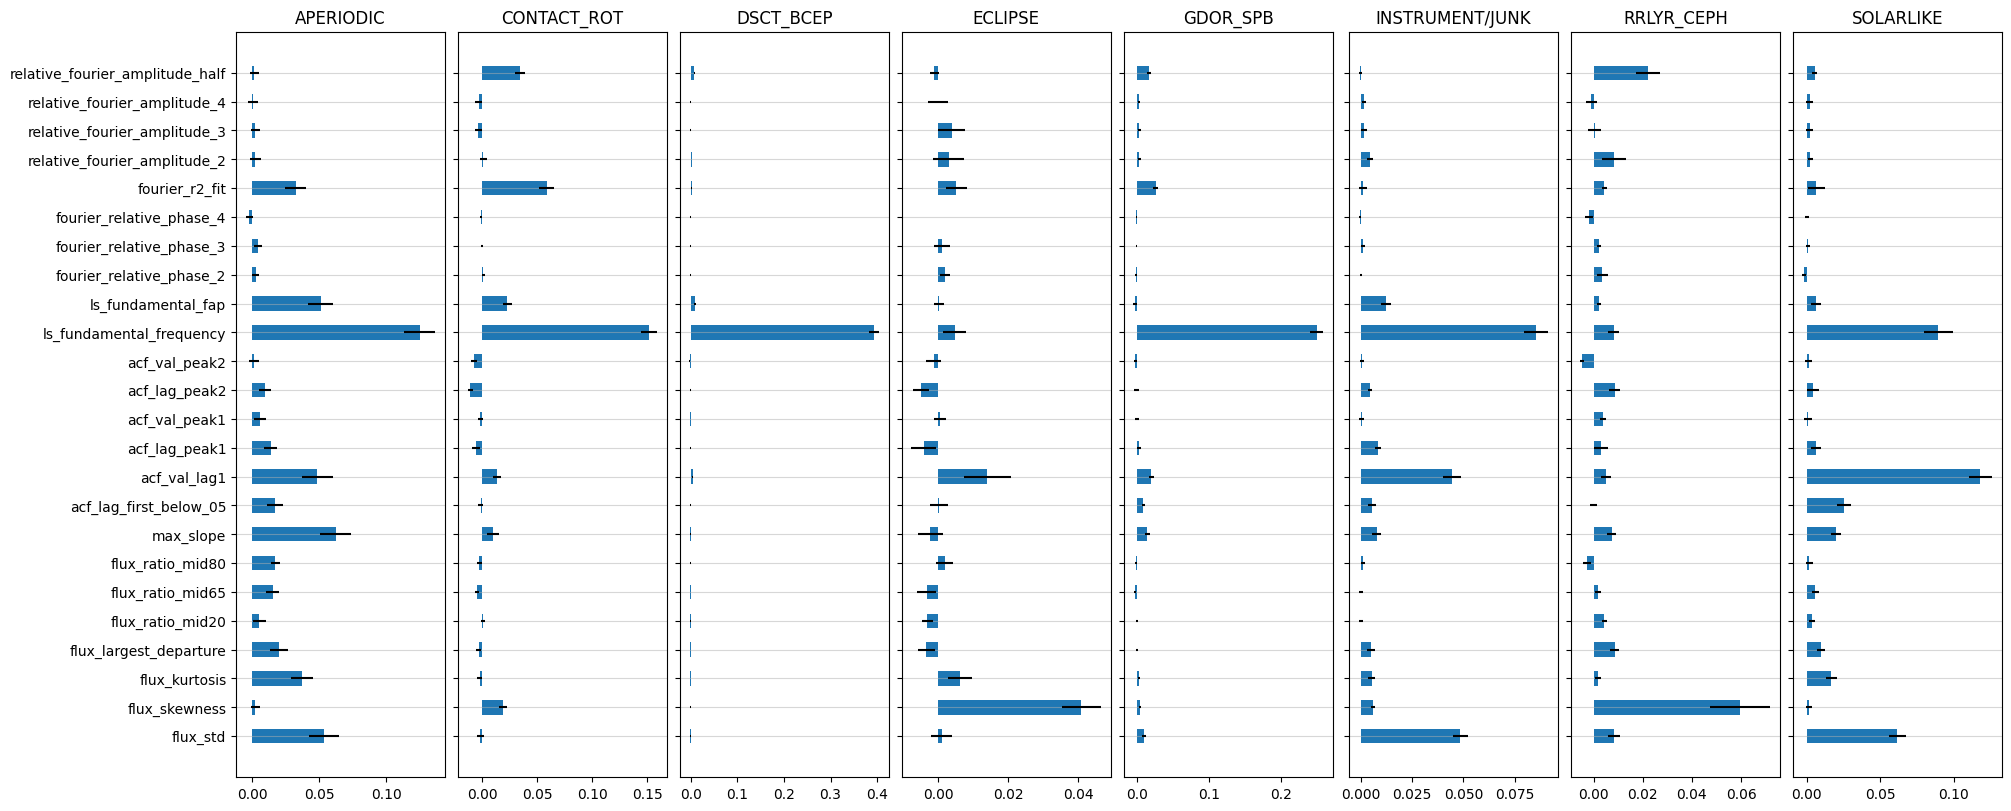

In [17]:
%%time
from sklearn.metrics import f1_score

best_rf = clf.best_estimator_
classes = np.unique(y_test)

def per_class_f1_scorer(estimator, X, y):
    y_pred = estimator.predict(X)
    return np.array([f1_score(y == c, y_pred == c) for c in classes], dtype=float)

pi_class = permutation_importance(best_rf, X_test_pre, y_test, scoring=per_class_f1_scorer, n_repeats=30, random_state=0, n_jobs=16)

fig, axs = plt.subplots(1, len(classes), figsize=(20, 8), sharey=True, constrained_layout=True)
for ax, name, pi_class_mean, pi_class_std in zip(axs, classes, pi_class.importances_mean.T, pi_class.importances_std.T):
    ax.barh(y=np.array(X_name)[np.array(selected_features)], width=pi_class_mean, xerr=pi_class_std, height=0.5)
    ax.set_title(name)
    ax.grid(axis='y', alpha=0.5)

In [18]:
from pickle import dump

y_all = np.concatenate([y_train, y_test])
y_pred_proba_all = np.concatenate([clf.predict_proba(X_train_pre), clf.predict_proba(X_test_pre)], axis=0)
all_paths = np.concatenate([path_train, path_test])

df_pred = pl.DataFrame({'path': all_paths} | {name: y_pred_proba_all[:, k] for k, name in enumerate(clf.classes_)})
display(df_pred.head())
save_path = Path('../results/classifications/training_set/')
save_path.mkdir(parents=True, exist_ok=True)
df_pred.write_parquet(save_path / 'predictions.parquet')

with open(save_path / 'model.pkl', "wb") as f:
    dump(clf, f, protocol=5)

path,APERIODIC,CONTACT_ROT,DSCT_BCEP,ECLIPSE,GDOR_SPB,INSTRUMENT/JUNK,RRLYR_CEPH,SOLARLIKE
str,f64,f64,f64,f64,f64,f64,f64,f64
"""/STER/mamsie/tess/TIC/tglc_scr…",0.004582,0.032263,0.008333,0.005464,0.070079,0.853629,0.0,0.02565
"""/STER/mamsie/tess/TIC/tglc_scr…",0.032074,0.001691,0.001381,0.000031,0.025156,0.004079,0.0,0.935587
"""/STER/mamsie/tess/TIC/tglc_scr…",0.000027,0.00064,0.999109,0.00007,0.000005,0.000063,0.0,0.000085
"""/STER/mamsie/tess/TIC/tglc_scr…",0.000048,0.010702,0.001002,0.000026,0.985125,0.000692,0.000015,0.002389
"""/STER/mamsie/tess/TIC/tglc_scr…",0.00009,0.943105,0.0,0.010102,0.032237,0.007018,0.006455,0.000993


## Visualization of feature space

CPU times: user 2min 7s, sys: 1.06 s, total: 2min 8s
Wall time: 1min 23s


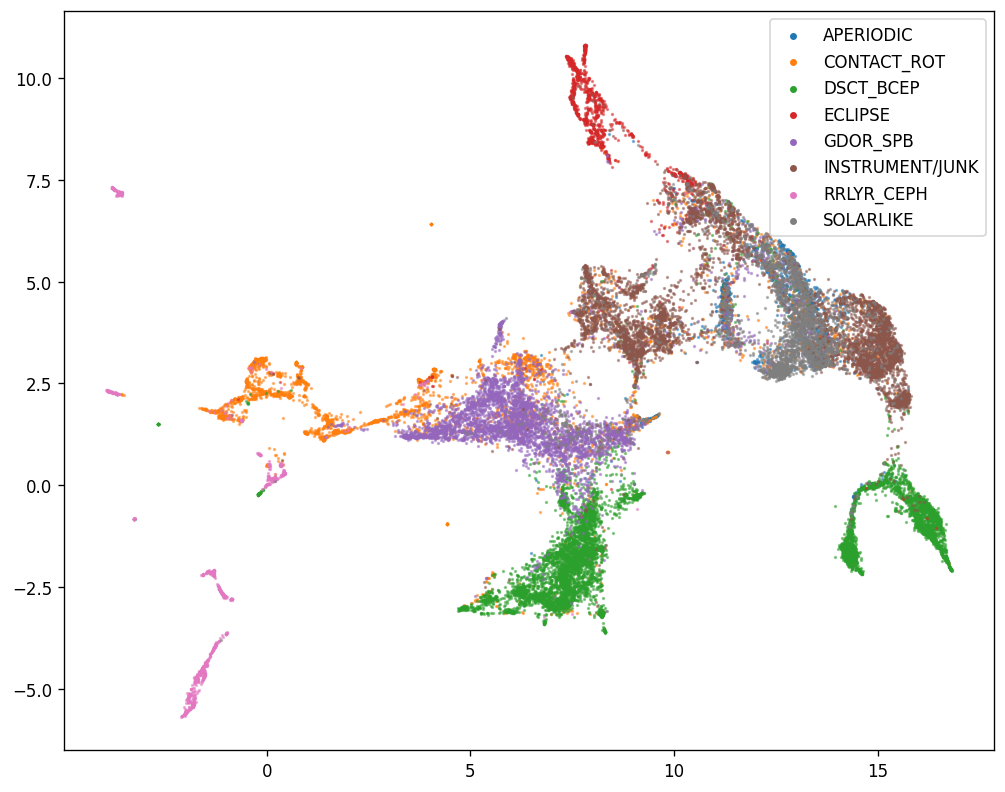

In [19]:
%%time
from umap import UMAP

projector = UMAP(n_components=2, min_dist=0.01, metric='euclidean', n_jobs=4, n_neighbors=25)
X_proj = projector.fit_transform(np.concatenate([X_train_pre, X_test_pre], axis=0))
y_proj = np.concatenate([y_train, y_test], axis=0)
fig, ax = plt.subplots(figsize=(10, 8), dpi=120)

for name in y_names:
    mask = y_proj == name
    ax.scatter(X_proj[mask, 0], X_proj[mask, 1], s=1, label=name, alpha=0.5)
leg = plt.legend()
for lh in leg.legend_handles:
    lh.set_alpha(1)
    lh._sizes = [10]

In [20]:
df_hv = pl.DataFrame({'lambda_1': X_proj[:, 0], 'lambda_2': X_proj[:, 1], 'class': y_proj, 'path': np.concatenate([path_train, path_test])})
df_hv = df_hv.join(df_training_features.select(['path', 'GaiaID', 'ls_fundamental_frequency']), on='path')
df_hv.write_parquet('viz.parquet')

## Error analysis

In [ ]:
y_all = np.concatenate([y_train, y_test])
y_pred_proba_all = np.concatenate([clf.predict_proba(X_train_pre), clf.predict_proba(X_test_pre)], axis=0)
y_pred_all = y_pred_proba_all.argmax(axis=1)
class_mapper = {k: v for k, v in enumerate(clf.classes_)}
inv_mapper = {v: k for k, v in class_mapper.items()}
y_pred_all = np.array([class_mapper[pred] for pred in y_pred_all])
y_entropy = -np.sum(y_pred_proba_all*np.log(y_pred_proba_all+1e-12), axis=1)/np.log(y_pred_proba_all.shape[1])

In [ ]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from light_curves import read_fits_lc
from frequency_domain_features import compute_lombscargle_periodogram

true_class = 'INSTRUMENT/JUNK'
true_class = 'APERIODIC'
true_class = 'ECLIPSE'
#true_class = 'CONTACT_ROT'
#pred_class = 'CONTACT_ROT'
#pred_class = 'INSTRUMENT/JUNK'
#pred_class = 'GDOR_SPB'
#pred_class = 'CONTACT_ROT'
pred_class = 'DSCT_BCEP'

analysis_mask = (y_all == true_class) & (y_pred_all == pred_class)
print(np.sum(analysis_mask))
analysis_path = np.concatenate([path_train, path_test])[analysis_mask]
df_analysis = pl.DataFrame(
    {'path': analysis_path, 'entropy': y_entropy[analysis_mask], 'proba_pred': y_pred_proba_all[analysis_mask][:, inv_mapper[pred_class]], 'proba_true': y_pred_proba_all[analysis_mask][:, inv_mapper[true_class]]}
).with_columns(
    pl.col('path').str.split('-').list.get(2).alias('sid'),
    pl.col('path').str.split('-').list.get(3).alias('sector')
).sort(['sid', 'sector']).unique('sid')

fig, axs = plt.subplots(max(2, df_analysis.height), 5, figsize=(20, 3*df_analysis.height), constrained_layout=True, sharex=False)
for row, ax in zip(df_analysis.iter_rows(named=True), axs):
    path_, proba, entropy, proba_true = row['path'], row['proba_pred'], row['entropy'], row['proba_true']
    sid, sector = path_.split('-')[2:4]
    ax[0].set_title(f"Gaia sid: {sid}, sector {sector}")
    ax[1].set_title(f"True: {true_class}={proba_true:0.3f}")
    ax[2].set_title(f"Pred: {pred_class}={proba:0.3f}, H={entropy:0.2f}")
    time, flux = read_fits_lc(path_, return_preprocessed=False)
    ax[0].scatter(time, flux, s=1)
    time, flux = read_fits_lc(path_, return_preprocessed=True)
    freq, ampl, _ = compute_lombscargle_periodogram(time, flux)
    best_freq = freq[np.argmax(ampl)]
    ax[1].scatter(time, flux, s=1)
    ax[2].plot(freq, ampl)
    ax[4].set_title(f"f={best_freq:0.4f}")
    ax[4].scatter(np.mod(time, 2/best_freq)*best_freq, flux, s=1)
    ax[3].plot(freq[freq<5], ampl[freq<5])
ax[0].set_xlabel('Time [d]')
ax[1].set_xlabel('Frequency [1/d]')
ax[2].set_xlabel('Phase');

In [ ]:
time[1:] - time[:-1]

In [ ]:
df_errors = pl.read_csv('plato_fov_relabling_effort_robust_outlier_filter.csv')
batch = 0

In [ ]:
batch = 257 // 20
batch

In [ ]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from light_curves import read_fits_lc
from frequency_domain_features import compute_lombscargle_periodogram

sample = df_errors.slice(batch*20, 20)
fig, axs = plt.subplots(20, 5, figsize=(17, 3*20), constrained_layout=True, sharex=False)
for k, (row, ax) in enumerate(zip(sample.iter_rows(named=True), axs)):
    sid, sector = row['path'].split('-')[2:4]
    label_, pred_ = row['label'], row['prediction']
    time, flux = read_fits_lc(row['path'], return_preprocessed=False)
    ax[0].scatter(time, flux, s=1)
    time, flux = read_fits_lc(row['path'], return_preprocessed=True)
    freq, ampl, _ = compute_lombscargle_periodogram(time, flux)
    best_freq = freq[np.argmax(ampl)]
    ax[1].scatter(time, flux, s=1)
    ax[2].plot(freq, ampl)
    ax[3].plot(freq[freq<5], ampl[freq<5])
    ax[4].scatter(np.mod(time, 2/best_freq)*best_freq, flux, s=1)
    ax[0].set_title(sid+" "+sector)
    ax[3].set_title(label_)
    ax[4].set_title(pred_)
ax[0].set_xlabel('Time [d]')
ax[1].set_xlabel('Frequency [1/d]')
ax[2].set_xlabel('Phase');
batch += 1

# Pathological cases

In [ ]:
# Light curve completely filtered by outlier processing
from light_curves import read_fits_lc, remove_outliers

time, flux = read_fits_lc(
    '/STER/mamsie/tess/TIC/tglc_scripts_plato_mit/s0026/cam1-ccd1/0020/9288/9154/7721/hlsp_tglc_tess_ffi_gaiaid-2092889154772199168-s0026-cam1-ccd1_tess_v1_llc.fits',
    return_preprocessed=False
)
plt.scatter(time, flux, s=1)
remove_outliers(time, flux, sigma_threshold=10)

In [ ]:
# Examples of extreme kurtosis

time, flux = read_fits_lc(
    '/STER/mamsie/tess/TIC/tglc_scripts_plato_mit/s0015/cam4-ccd4/0015/5667/2589/6237/hlsp_tglc_tess_ffi_gaiaid-1556672589623717632-s0015-cam4-ccd4_tess_v1_llc.fits',
    #'/STER/mamsie/tess/TIC/tglc_scripts_plato_mit/s0015/cam4-ccd4/0015/5697/4061/9678/hlsp_tglc_tess_ffi_gaiaid-1556974061967876096-s0015-cam4-ccd4_tess_v1_llc.fits',
    return_preprocessed=False
)
plt.scatter(time, flux, s=1)

In [ ]:
# Random light curves for reference of what is normal

fig, axs = plt.subplots(3, 3, figsize=(8, 6), constrained_layout=True)
for path, ax in zip(df_training_features.sample(9)['path'].to_list(), axs.ravel()):
    time, flux = read_fits_lc(path, return_preprocessed=True)
    ax.scatter(time, flux, s=1)

In [ ]:
# Examples of light curve with extreme values of certain features

extreme_cols = ['flux_std', 'flux_skewness', 'flux_kurtosis', 'max_slope', 'fourier_amplitude_2']
for col in extreme_cols:
    fig, axs = plt.subplots(3, 3, figsize=(8, 6), constrained_layout=True)
    for path, ax in zip(df_training_features.sort(col).tail(9)['path'].to_list(), axs.ravel()):
        time, flux = read_fits_lc(path, return_preprocessed=False)
        ax.scatter(time, flux, s=1)
    fig.suptitle(col, fontsize=14)

In [ ]:
# Examples of light curve with extreme values of certain features

extreme_cols = ['flux_std', 'flux_skewness', 'flux_kurtosis', 'max_slope', 'fourier_amplitude_2']
for col in extreme_cols:
    fig, axs = plt.subplots(3, 3, figsize=(8, 6), constrained_layout=True)
    for path, ax in zip(df_training_features.sort(col).tail(9)['path'].to_list(), axs.ravel()):
        time, flux = read_fits_lc(path, return_preprocessed=True)
        ax.scatter(time, flux, s=1)
    fig.suptitle(col, fontsize=14)

# Inference data

In [ ]:
# Light curves per sector
total_rows = 0
for sector_parquet in sorted(list((plato_data_directory / 'paths').glob('*.parquet'))):
    n_rows = pl.scan_parquet(sector_parquet).select(pl.len()).collect().item()
    total_rows += n_rows
    print(sector_parquet.stem, f"{n_rows:_}".replace("_", " "))
print(f'Total: {total_rows:_}')

In [ ]:
index = pl.scan_parquet(sector_parquet).head(5).collect().to_series().to_list()
index

In [ ]:
# Example of feature extraction

from feature_extractors import extract_features_from_path

extract_features_from_path(index[0])

In [ ]:
%%time
# Example of feature extraction in parallel
from feature_extractors import extract_features_parallel

extract_features_parallel(index, n_jobs=1, backend='loky', worker_batch_size=5)